## Read the data

In [5]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

In [6]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/evaluation_results/"
TARGET_LENGTHS = [9]

In [7]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")

ALLELES

['HLA-A*01:01', 'HLA-A*02:01', 'HLA-A*03:01', 'HLA-B*07:02', 'HLA-B*27:05']

# Read decoy

In [8]:
from mhcgnomes import parse
# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None

def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None


per_allele_decoy = dict()
for allele_name in ALLELES:
    organism =  defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"D:\Google Drive\Work\ITMO\data\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df =  pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()

    #filter decoy
    decoy_df = decoy_df[decoy_df['length'].isin(TARGET_LENGTHS)]
    per_allele_decoy[allele_name] = decoy_df.copy()


In [9]:
per_allele_decoy[ALLELES[0]].length.value_counts()

9    401984
Name: length, dtype: int64

# Read models

In [10]:
from hmm_logic_methods import load_model

In [14]:
import itertools

RUNS = 2
target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
max_target_length = max(TARGET_LENGTHS)
total_splits = 1


name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
selected_binding_models = list()
per_name_binding_model = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type




MODELS_PATH = "experiment_results/many_states/"
states = 40

for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    for run_num_b in range(RUNS):
        for split_num_b in range(total_splits):
            bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}"
            populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, "bw")
            bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_plus_viterbi"
            populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, "bwv")

MODELS_PATH = "experiment_results/iterative/"
states = 4

for allele_name in ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    for run_num_b in range(RUNS):
        for split_num_b in range(total_splits):
            #bw
            bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_iterations_to_length_{max_target_length}"
            populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, "bw-it")
            #bwv
            bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_iterations_to_length_{max_target_length}_plus_viterbi"
            populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, "bwv-it")
            #v
            v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_iterations_to_length_{max_target_length}"
            populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, "v-it")


MODELS_PATH = "experiment_results/iterative_alleles/"
states = 4
MIXED_ALLELES = list()
for allele_name1, allele_name2 in itertools.combinations(ALLELES, 2):
    allele_name = f"{allele_name1}+{allele_name2}"
    MIXED_ALLELES.append(allele_name)

for allele_name in MIXED_ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    for run_num_b in range(RUNS):
        for split_num_b in range(total_splits):
            #bw
            bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_iterations_to_length_{max_target_length}"
            populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})")
            #bwv
            bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_iterations_to_length_{max_target_length}_plus_viterbi"
            populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})")
            #v
            v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_iterations_to_length_{max_target_length}"
            populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})")


for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)


# Get scores for decoy (per allele)

In [17]:
%%time
for allele_name, decoy_df in per_allele_decoy.items():
    print(f"{allele_name}:", end=" ")
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    for model_num, (model_name, model) in enumerate(per_name_binding_model.items()):

        if target_allele_name in model_name:
            print(model_num, end=" ")
            model_split = name_to_split[model_name]
            model_run = name_to_run[model_name]
            model_type = name_to_type[model_name]

            model_code = f"{model_type}-({model_run}-{model_split})"
            decoy_df[model_code] = [model.log_probability(peptide) for peptide in decoy_df['peptide'].values]
    print()

HLA-A*01:01: 0 1 2 3 20 21 22 23 24 25 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 
HLA-A*02:01: 4 5 6 7 26 27 28 29 30 31 50 51 52 53 54 55 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 
HLA-A*03:01: 8 9 10 11 32 33 34 35 36 37 56 57 58 59 60 61 74 75 76 77 78 79 92 93 94 95 96 97 98 99 100 101 102 103 
HLA-B*07:02: 12 13 14 15 38 39 40 41 42 43 62 63 64 65 66 67 80 81 82 83 84 85 92 93 94 95 96 97 104 105 106 107 108 109 
HLA-B*27:05: 16 17 18 19 44 45 46 47 48 49 68 69 70 71 72 73 86 87 88 89 90 91 98 99 100 101 102 103 104 105 106 107 108 109 
Wall time: 50min 5s


## Calculate mean

In [46]:
for allele_name, decoy_df in per_allele_decoy.items():
    decoy_df.replace([np.inf, -np.inf], -55, inplace=True)
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')

    for model_type in set(name_to_type.values()):
        if target_allele_name in model_type or "mixed" not in model_type:
            selected_columns = [column for column in decoy_df.columns if column.startswith(f"{model_type}-(") ]
            decoy_df[f"{model_type}-mean"] = decoy_df[selected_columns].mean(axis=1)



## Calculate percentiles for decoy

In [48]:
def get_percentile_ranks(scores, ref_scores):
    ref_scores = ref_scores.sort_values()
    pct_increment = 1./len(ref_scores)
    percentile_ranks = (0.5 + 0.5*ref_scores.searchsorted(scores, side='left') + 0.5 * ref_scores.searchsorted(scores, side='right'))*pct_increment
    percentile_ranks = 100 - percentile_ranks*100
    return percentile_ranks



for allele_name, decoy_df in per_allele_decoy.items():

    decoy_df.replace([np.inf, -np.inf], -55, inplace=True)
    for score_column in decoy_df.columns:
        if score_column.endswith("mean"):
            if score_column not in ["peptide", "length"]:
                decoy_df[f'percentile_{score_column}'] = get_percentile_ranks(decoy_df[score_column], decoy_df[score_column])


In [49]:
decoy_df.describe()

,length,bw-(0-0),bwv-(0-0),bw-(1-0),bwv-(1-0),bw-it-(0-0),bwv-it-(0-0),v-it-(0-0),bw-it-(1-0),bwv-it-(1-0),...,percentile_bwv-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,percentile_v-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,percentile_bw-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,percentile_v-it-mean,percentile_bwv-it-mean,percentile_bw-mean,percentile_bwv-it-mixed(HLA_A_03_01+HLA_B_27_05)-mean,percentile_v-it-mixed(HLA_B_07_02+HLA_B_27_05)-mean,percentile_bw-it-mixed(HLA_A_03_01+HLA_B_27_05)-mean,percentile_bwv-it-mixed(HLA_B_07_02+HLA_B_27_05)-mean
count,401984.0,401984.000000,401984.000000,401984.000000,401984.000000,401984.000000,401984.000000,401984.000000,401984.000000,401984.000000,...,401984.000000,401984.000000,401984.000000,401984.000000,401984.000000,401984.000000,401984.000000,401984.000000,401984.000000,401984.000000
mean,9.0,-28.434919,-28.897237,-28.419248,-28.785044,-28.453624,-28.711402,-28.539118,-28.497888,-28.640966,...,49.999876,49.999876,49.999876,49.999876,49.999876,49.999876,49.999876,49.999876,49.999876,49.999876
std,0.0,2.636258,2.892064,2.623937,2.844372,2.664686,2.854528,2.732848,2.731213,2.793441,...,28.867549,28.867549,28.867549,28.867549,28.867549,28.867549,28.867549,28.867549,28.867549,28.867549
min,9.0,-46.179259,-55.000000,-46.216542,-55.000000,-46.344230,-49.313347,-46.716658,-47.110503,-55.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,9.0,-30.074293,-30.705365,-30.047241,-30.534583,-30.111558,-30.434358,-30.233942,-30.187850,-30.345717,...,24.999938,24.999938,24.999938,24.999938,24.999938,24.999938,24.999938,24.999938,24.999938,24.999938
50%,9.0,-28.396399,-28.809544,-28.382997,-28.706253,-28.402211,-28.589395,-28.478208,-28.418012,-28.559706,...,49.999876,49.999876,49.999876,49.999876,49.999876,49.999876,49.999876,49.999876,49.999876,49.999876
75%,9.0,-26.658938,-26.951689,-26.655472,-26.877151,-26.659125,-26.784857,-26.704041,-26.655603,-26.771611,...,74.999813,74.999813,74.999813,74.999813,74.999813,74.999813,74.999813,74.999813,74.999813,74.999813
max,9.0,-16.485963,-15.868955,-16.674591,-16.646155,-16.629577,-16.673141,-16.643880,-16.919115,-16.540770,...,99.999751,99.999751,99.999751,99.999751,99.999751,99.999751,99.999751,99.999751,99.999751,99.999751


## Save decoy predictions to files

In [50]:
import os
if not os.path.exists(TARGET_PATH_TO_RESULTS):
    os.makedirs(TARGET_PATH_TO_RESULTS)
for allele_name, decoy_df in per_allele_decoy.items():
    decoy_df = decoy_df[['peptide', 'length'] + [column for column in decoy_df.columns if "mean" in column]]
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')

    decoy_df.to_csv(f'{TARGET_PATH_TO_RESULTS}decoy_predictions_{target_allele_name}.csv', index=False)

## Make predictions for test data

In [64]:
per_allele_binders_df = dict()
per_allele_non_binders_df = dict()
for allele_name in ALLELES:
    binders_test = per_allele_per_kfold_per_length_binders_test[allele_name][0][9]
    non_binders_test = per_allele_per_kfold_per_length_non_binders_test[allele_name][0][9]
    binders_df = pd.DataFrame({'peptide': binders_test})
    non_binders_df = pd.DataFrame({'peptide': non_binders_test})
    print(f"{allele_name}:", end=" ")
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    for model_num, (model_name, model) in enumerate(per_name_binding_model.items()):

        if target_allele_name in model_name:
            print(model_num, end=" ")
            model_split = name_to_split[model_name]
            model_run = name_to_run[model_name]
            model_type = name_to_type[model_name]

            model_code = f"{model_type}-({model_run}-{model_split})"

            binders_df[model_code] = [model.log_probability(peptide) for peptide in binders_df['peptide'].values]
            non_binders_df[model_code] = [model.log_probability(peptide) for peptide in non_binders_df['peptide'].values]
    binders_df.replace([np.inf, -np.inf], -55, inplace=True)
    non_binders_df.replace([np.inf, -np.inf], -55, inplace=True)
    for model_type in set(name_to_type.values()):
        if target_allele_name in model_type or "mixed" not in model_type:
            selected_columns = [column for column in binders_df.columns if column.startswith(f"{model_type}-(") ]
            binders_df[f"{model_type}-mean"] = binders_df[selected_columns].mean(axis=1)
            non_binders_df[f"{model_type}-mean"] = non_binders_df[selected_columns].mean(axis=1)


    print()
    binders_df = binders_df[["peptide"] + [column for column in binders_df.columns if "mean" in column]]
    non_binders_df = non_binders_df[["peptide"] + [column for column in non_binders_df.columns if "mean" in column]]

    per_allele_binders_df[allele_name] = binders_df
    per_allele_non_binders_df[allele_name] = non_binders_df


HLA-A*01:01: 0 1 2 3 20 21 22 23 24 25 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72 73 
HLA-A*02:01: 4 5 6 7 26 27 28 29 30 31 50 51 52 53 54 55 74 75 76 77 78 79 80 81 82 83 84 85 86 87 88 89 90 91 
HLA-A*03:01: 8 9 10 11 32 33 34 35 36 37 56 57 58 59 60 61 74 75 76 77 78 79 92 93 94 95 96 97 98 99 100 101 102 103 
HLA-B*07:02: 12 13 14 15 38 39 40 41 42 43 62 63 64 65 66 67 80 81 82 83 84 85 92 93 94 95 96 97 104 105 106 107 108 109 
HLA-B*27:05: 16 17 18 19 44 45 46 47 48 49 68 69 70 71 72 73 86 87 88 89 90 91 98 99 100 101 102 103 104 105 106 107 108 109 


In [66]:
binders_df.describe()

,v-it-mixed(HLA_A_03_01+HLA_B_27_05)-mean,bw-it-mean,bw-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,bwv-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,v-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,bwv-mean,bw-it-mixed(HLA_B_07_02+HLA_B_27_05)-mean,bwv-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,v-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,bw-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,v-it-mean,bwv-it-mean,bw-mean,bwv-it-mixed(HLA_A_03_01+HLA_B_27_05)-mean,v-it-mixed(HLA_B_07_02+HLA_B_27_05)-mean,bw-it-mixed(HLA_A_03_01+HLA_B_27_05)-mean,bwv-it-mixed(HLA_B_07_02+HLA_B_27_05)-mean
count,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000
mean,-23.717616,-23.485158,-23.742425,-24.396759,-24.335046,-23.664381,-23.984009,-23.856962,-23.764506,-24.357771,-23.544727,-23.557651,-23.414106,-23.791759,-24.005791,-23.728211,-24.048494
std,2.462701,2.561354,2.345543,2.402047,2.341357,2.742438,2.457092,2.564896,2.330665,2.323543,2.580666,2.683757,2.565873,2.554875,2.459406,2.461513,2.634349
min,-34.265400,-33.372029,-33.528092,-34.462514,-34.687443,-34.339609,-33.947526,-40.687754,-33.511274,-34.675131,-33.560798,-33.971863,-33.333436,-41.728652,-33.950545,-34.419108,-34.898996
25%,-25.230083,-25.108209,-25.156631,-25.764039,-25.680383,-25.364935,-25.460290,-25.397998,-25.168117,-25.681974,-25.165165,-25.284195,-25.043997,-25.346577,-25.473449,-25.245319,-25.580810
50%,-23.309728,-23.074917,-23.394418,-24.135094,-24.085776,-23.276669,-23.662687,-23.468231,-23.407434,-24.105690,-23.122673,-23.175152,-23.042214,-23.407833,-23.689609,-23.305704,-23.715967
75%,-21.898530,-21.552508,-22.017798,-22.756275,-22.699975,-21.635510,-22.226493,-22.009658,-22.061927,-22.723050,-21.618927,-21.554011,-21.482240,-21.918655,-22.269087,-21.904095,-22.145543
max,-18.115291,-17.388923,-18.059961,-17.992725,-18.029983,-17.077387,-18.092343,-17.663787,-17.903507,-18.126614,-17.575802,-17.251764,-17.198754,-17.753136,-17.928695,-18.258786,-17.621172


In [67]:
## Percentiles

In [68]:
for allele_name in ALLELES:
    decoy_df = per_allele_decoy[allele_name]
    binders_df = per_allele_binders_df[allele_name]
    non_binders_df = per_allele_non_binders_df[allele_name]
    for score_column in binders_df.columns:
        if score_column.endswith("mean"):
            if score_column not in ["peptide", "length"]:
                binders_df[f'percentile_{score_column}'] = get_percentile_ranks(binders_df[score_column], decoy_df[score_column])
                non_binders_df[f'percentile_{score_column}'] = get_percentile_ranks(non_binders_df[score_column], decoy_df[score_column])



In [72]:
binders_df.describe()

,v-it-mixed(HLA_A_03_01+HLA_B_27_05)-mean,bw-it-mean,bw-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,bwv-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,v-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,bwv-mean,bw-it-mixed(HLA_B_07_02+HLA_B_27_05)-mean,bwv-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,v-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,bw-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,...,percentile_bwv-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,percentile_v-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,percentile_bw-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,percentile_v-it-mean,percentile_bwv-it-mean,percentile_bw-mean,percentile_bwv-it-mixed(HLA_A_03_01+HLA_B_27_05)-mean,percentile_v-it-mixed(HLA_B_07_02+HLA_B_27_05)-mean,percentile_bw-it-mixed(HLA_A_03_01+HLA_B_27_05)-mean,percentile_bwv-it-mixed(HLA_B_07_02+HLA_B_27_05)-mean
count,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,...,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000,4350.000000
mean,-23.717616,-23.485158,-23.742425,-24.396759,-24.335046,-23.664381,-23.984009,-23.856962,-23.764506,-24.357771,...,9.862608,9.870283,13.544643,9.471856,9.459218,8.984561,10.161403,11.199764,10.186736,11.060788
std,2.462701,2.561354,2.345543,2.402047,2.341357,2.742438,2.457092,2.564896,2.330665,2.323543,...,17.002458,16.572866,18.182918,16.543422,16.897572,16.307867,16.881860,17.075081,16.795949,17.517736
min,-34.265400,-33.372029,-33.528092,-34.462514,-34.687443,-34.339609,-33.947526,-40.687754,-33.511274,-34.675131,...,0.000373,0.000498,0.001119,0.000373,0.000373,0.000373,0.000373,0.000124,0.000373,0.000124
25%,-25.230083,-25.108209,-25.156631,-25.764039,-25.680383,-25.364935,-25.460290,-25.397998,-25.168117,-25.681974,...,0.453003,0.541813,1.861455,0.426074,0.347837,0.336954,0.524523,1.012478,0.550644,0.834299
50%,-23.309728,-23.074917,-23.394418,-24.135094,-24.085776,-23.276669,-23.662687,-23.468231,-23.407434,-24.105690,...,2.105681,2.415581,6.028225,1.806540,1.676186,1.575187,2.545126,3.751269,2.497985,3.443421
75%,-21.898530,-21.552508,-22.017798,-22.756275,-22.699975,-21.635510,-22.226493,-22.009658,-22.061927,-22.723050,...,10.811438,11.218233,16.832946,10.212098,10.265956,9.343220,11.787969,13.272046,11.986236,12.612194
max,-18.115291,-17.388923,-18.059961,-17.992725,-18.029983,-17.077387,-18.092343,-17.663787,-17.903507,-18.126614,...,99.964302,97.257727,98.976949,96.139274,96.628846,96.336546,99.934201,96.997517,98.242094,97.098268


In [71]:
non_binders_df.describe()

,v-it-mixed(HLA_A_03_01+HLA_B_27_05)-mean,bw-it-mean,bw-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,bwv-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,v-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,bwv-mean,bw-it-mixed(HLA_B_07_02+HLA_B_27_05)-mean,bwv-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,v-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,bw-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,...,percentile_bwv-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,percentile_v-it-mixed(HLA_A_01_01+HLA_B_27_05)-mean,percentile_bw-it-mixed(HLA_A_02_01+HLA_B_27_05)-mean,percentile_v-it-mean,percentile_bwv-it-mean,percentile_bw-mean,percentile_bwv-it-mixed(HLA_A_03_01+HLA_B_27_05)-mean,percentile_v-it-mixed(HLA_B_07_02+HLA_B_27_05)-mean,percentile_bw-it-mixed(HLA_A_03_01+HLA_B_27_05)-mean,percentile_bwv-it-mixed(HLA_B_07_02+HLA_B_27_05)-mean
count,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000,...,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000,1937.000000
mean,-24.958648,-24.913576,-24.958319,-25.455021,-25.346073,-25.204459,-25.068525,-25.182555,-24.949169,-25.358709,...,18.934027,18.603484,22.137305,19.042278,19.503401,18.806454,18.906269,20.026834,18.938856,20.376910
std,2.840043,2.987101,2.682414,2.782299,2.721262,3.139303,2.964017,2.881359,2.673404,2.709118,...,23.292664,22.729525,24.319077,23.790822,24.529726,23.758393,23.130206,24.166463,23.102538,24.470856
min,-34.715632,-34.267471,-33.240504,-35.514587,-34.764150,-36.179294,-34.570132,-34.169324,-33.504373,-34.815962,...,0.000000,0.000249,0.001244,0.000249,0.000000,0.000000,0.000124,0.000249,0.000124,0.000249
25%,-26.930022,-26.937276,-26.784860,-27.294965,-27.142650,-27.447424,-27.164555,-27.220313,-26.768657,-27.124958,...,1.300922,1.358387,3.356601,1.067082,1.088974,1.009120,1.349681,1.599442,1.385254,1.461128
50%,-24.800272,-24.864763,-24.881310,-25.242870,-25.085813,-25.229095,-24.908668,-25.071935,-24.840857,-25.105337,...,8.546982,8.791519,11.954332,8.204431,8.628826,8.075321,8.715645,9.193276,8.893513,9.062177
75%,-22.715715,-22.586099,-22.856559,-23.441941,-23.349550,-22.859132,-22.739073,-22.986395,-22.852321,-23.382983,...,29.377164,27.950491,33.474093,29.568963,28.678131,28.143036,28.399762,31.800395,28.945306,32.326287
max,-17.416745,-17.037390,-17.546261,-18.534648,-17.974587,-16.257555,-17.936556,-16.871939,-17.647087,-18.149140,...,97.256980,97.245288,99.089143,97.383354,99.674987,98.125423,98.559520,98.608029,98.520215,99.915793


# Select 2 mixed models BW and BWV

In [1]:
import importlib
import hmm_logic_methods
importlib.reload(hmm_logic_methods)

<module 'hmm_logic_methods' from 'D:\\Projects\\MHC_predictor\\experiments\\length_dependent_hmm\\hmm_logic_methods.py'>

In [214]:

mixed_model_bw ='0_run-9-4-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_iterations_to_length_9'
mixed_model_bwv = '0_run-9-4-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_iterations_to_length_9_plus_viterbi'
mixed_model_v = '0_run-9-4-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_iterations_to_length_9'

In [215]:
# Get top paths
from hmm_logic_methods import get_all_paths_with_probs, get_model_representation


In [216]:
model_bw = per_name_binding_model[mixed_model_bw]
model_bwv = per_name_binding_model[mixed_model_bwv]
model_v = per_name_binding_model[mixed_model_v]

model_list = [model_bw, model_bwv, model_v]


# Calculate paths embeddings (10.01.22)

In [179]:
df_bw_paths, edge_to_prob_bw = get_all_paths_with_probs(model_bw)
df_bwv_paths, edge_to_prob_bwv = get_all_paths_with_probs(model_bwv)
df_v_paths, edge_to_prob_v = get_all_paths_with_probs(model_v)

Converting graph for model (0_run-9-4-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_iterations_to_length_9) (Delete zero edges)
found 262144 paths


100%|██████████| 262144/262144 [00:01<00:00, 148775.22it/s]


Converting graph for model (0_run-9-4-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_iterations_to_length_9_plus_viterbi) (Delete zero edges)
found 116736 paths


100%|██████████| 116736/116736 [00:00<00:00, 141326.96it/s]


Converting graph for model (0_run-9-4-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01-0_iterations_to_length_9) (Delete zero edges)
found 262144 paths


100%|██████████| 262144/262144 [00:01<00:00, 147354.77it/s]


In [180]:
df_v_paths

,path,prob
199461,[0_run-9-4-st-viterbi-alg-5-min_iters_model-HL...,-7.309769
199525,[0_run-9-4-st-viterbi-alg-5-min_iters_model-HL...,-7.419390
133925,[0_run-9-4-st-viterbi-alg-5-min_iters_model-HL...,-7.423249
68389,[0_run-9-4-st-viterbi-alg-5-min_iters_model-HL...,-7.429089
199589,[0_run-9-4-st-viterbi-alg-5-min_iters_model-HL...,-7.443490
...,...,...
62155,[0_run-9-4-st-viterbi-alg-5-min_iters_model-HL...,-24.359307
53962,[0_run-9-4-st-viterbi-alg-5-min_iters_model-HL...,-24.521852
53963,[0_run-9-4-st-viterbi-alg-5-min_iters_model-HL...,-24.521852
63178,[0_run-9-4-st-viterbi-alg-5-min_iters_model-HL...,-24.623777


In [2]:
%%time
target_length = 9
TOP=1000
allele_1 = 'HLA-A*01:01'
allele_2 = 'HLA-A*03:01'
binders1 = per_allele_binders_df[allele_1]['peptide'].values
binders2 = per_allele_binders_df[allele_2]['peptide'].values

per_allele_representations_train = dict()
per_allele_representations_test = dict()
per_name_representation_train = dict()
per_name_representation_test = dict()
train_peptides_b1 = set(per_allele_per_kfold_per_length_binders_train[allele_1][0][target_length])
train_peptides_b2 =  set(per_allele_per_kfold_per_length_binders_train[allele_2][0][target_length])

train_peptides_b = train_peptides_b1.union(train_peptides_b2)
# train_peptides_b = train_peptides_b1.copy()
# train_peptides_b = train_peptides_b.update(train_peptides_b2)
train_allele_1_cnt = len(train_peptides_b1)
train_allele_2_cnt = len(train_peptides_b2.difference(train_peptides_b1))

test_peptides_b1 =  set(per_allele_per_kfold_per_length_binders_test[allele_1][0][target_length])
test_peptides_b2 =  set(per_allele_per_kfold_per_length_binders_test[allele_2][0][target_length])
test_peptides_b = test_peptides_b1.union(test_peptides_b2)

test_allele_1_cnt = len(test_peptides_b1)
test_allele_2_cnt = len(test_peptides_b2.difference(test_peptides_b1))
print("Train")
train_peptides_repr_data_b_model_bw, _ = get_model_representation(model_bw, set(train_peptides_b), edge_value="log_probability", top_paths=TOP)
train_peptides_repr_data_b_model_bw['allele'] = [allele_1] * train_allele_1_cnt + [allele_2] * train_allele_2_cnt
train_peptides_repr_data_b_model_bwv, _ = get_model_representation(model_bwv, set(train_peptides_b), edge_value="log_probability", top_paths=TOP)
train_peptides_repr_data_b_model_bwv['allele'] = [allele_1] * train_allele_1_cnt + [allele_2]* train_allele_2_cnt
train_peptides_repr_data_b_model_v, _ = get_model_representation(model_v, set(train_peptides_b), edge_value="log_probability", top_paths=TOP)
train_peptides_repr_data_b_model_v['allele'] = [allele_1] * train_allele_1_cnt + [allele_2]* train_allele_2_cnt

print("Test")
test_peptides_repr_data_b_model_bw, _ = get_model_representation(model_bw, set(test_peptides_b), edge_value="log_probability",  top_paths=TOP)
test_peptides_repr_data_b_model_bw['allele'] = [allele_1] * test_allele_1_cnt + [allele_2]* test_allele_2_cnt
test_peptides_repr_data_b_model_bwv, _ = get_model_representation(model_bwv, set(test_peptides_b), edge_value="log_probability",  top_paths=TOP)
test_peptides_repr_data_b_model_bwv['allele'] = [allele_1] * test_allele_1_cnt + [allele_2]* test_allele_2_cnt
test_peptides_repr_data_b_model_v, _ = get_model_representation(model_v, set(test_peptides_b), edge_value="log_probability",  top_paths=TOP)
test_peptides_repr_data_b_model_v['allele'] = [allele_1] * test_allele_1_cnt + [allele_2]* test_allele_2_cnt


per_name_representation_train["bw"] = {"db": train_peptides_repr_data_b_model_bw  }
per_name_representation_train["bwv"] = {"db": train_peptides_repr_data_b_model_bwv  }
per_name_representation_train["v"] = {"db": train_peptides_repr_data_b_model_v  }
per_name_representation_test["bw"] = {"db": test_peptides_repr_data_b_model_bw  }
per_name_representation_test["bwv"] = {"db": test_peptides_repr_data_b_model_bwv  }
per_name_representation_test["v"] = {"db": test_peptides_repr_data_b_model_v  }


NameError: name 'per_allele_binders_df' is not defined

In [173]:
per_name_representation_train["v"]["db"].describe()

path_index,0,1,2,3,4,5,6,7,8,9,...,990,991,992,993,994,995,996,997,998,999
count,9364.000000,9364.0,9364.000000,9364.000000,9364.000000,9364.0,9364.0,9364.000000,9364.000000,9364.0,...,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.0
mean,-54.993255,-55.0,-54.996657,-54.993772,-54.989856,-55.0,-55.0,-54.989549,-54.996817,-55.0,...,-54.989152,-54.993076,-54.996760,-54.996381,-54.996500,-54.996891,-54.996556,-54.989724,-54.992793,-55.0
std,0.461801,0.0,0.323505,0.429122,0.567359,0.0,0.0,0.584724,0.307980,0.0,...,0.606016,0.473909,0.313527,0.350168,0.338689,0.300819,0.333225,0.574368,0.493168,0.0
min,-55.000000,-55.0,-55.000000,-55.000000,-55.000000,-55.0,-55.0,-55.000000,-55.000000,-55.0,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.0
25%,-55.000000,-55.0,-55.000000,-55.000000,-55.000000,-55.0,-55.0,-55.000000,-55.000000,-55.0,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.0
50%,-55.000000,-55.0,-55.000000,-55.000000,-55.000000,-55.0,-55.0,-55.000000,-55.000000,-55.0,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.0
75%,-55.000000,-55.0,-55.000000,-55.000000,-55.000000,-55.0,-55.0,-55.000000,-55.000000,-55.0,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.0
max,-22.346010,-55.0,-23.695114,-22.377221,-22.086418,-55.0,-55.0,-20.724467,-25.197426,-55.0,...,-20.831761,-21.709673,-24.660698,-21.115061,-22.225866,-25.890466,-22.754581,-21.850827,-20.781011,-55.0


In [189]:
per_name_representation_train["bwv"]["db"][0].idxmax()


'VTDLAGNEY'

In [178]:
per_name_representation_train["v"]["db"]

path_index,0,1,2,3,4,5,6,7,8,9,...,991,992,993,994,995,996,997,998,999,allele
peptide,,,,,,,,,,,,,,,,,,,,,
AAAAALQAK,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*01:01
AAAACTTMK,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*01:01
AAAAGGAGY,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*01:01
AAAALGRAP,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*01:01
AAAERDVVY,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*01:01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YYDYISPRF,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*03:01
YYEEQHPEL,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*03:01
YYELAQVLL,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*03:01


In [202]:
per_name_representation_train["bwv"]["db"]

path_index,0,1,2,3,4,5,6,7,8,9,...,991,992,993,994,995,996,997,998,999,allele
peptide,,,,,,,,,,,,,,,,,,,,,
AAAAALQAK,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*01:01
AAAACTTMK,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*01:01
AAAAGGAGY,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*01:01
AAAALGRAP,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*01:01
AAAERDVVY,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*01:01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
YYDYISPRF,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*03:01
YYEEQHPEL,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*03:01
YYELAQVLL,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,...,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,-55.0,HLA-A*03:01


In [205]:
import seaborn as sns

In [207]:
len([len(per_name_representation_train["v"]["db"][per_name_representation_train["bwv"]["db"][i] != -55]) for i in range(1000)])

1000

<AxesSubplot:>

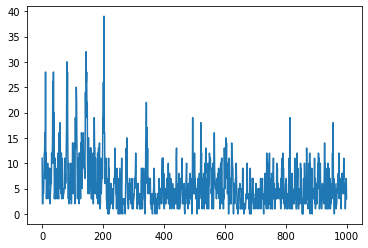

In [212]:
sns.lineplot(x=[i for i in range(1000)],y=[len(per_name_representation_train["v"]["db"][per_name_representation_train["bwv"]["db"][i] != -55]) for i in range(1000)])

<AxesSubplot:ylabel='Count'>

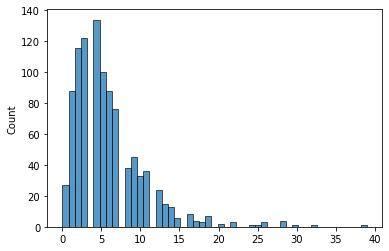

In [206]:
sns.histplot([len(per_name_representation_train["v"]["db"][per_name_representation_train["bwv"]["db"][i] != -55]) for i in range(1000)])

In [168]:
per_name_representation_train["v"]["db"].describe()

path_index,0,1,2,3,4,5,6,7,8,9,...,290,291,292,293,294,295,296,297,298,299
count,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,...,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.0,9364.000000,9364.000000,9364.000000
mean,-54.989625,-54.986486,-54.996414,-54.986346,-54.986217,-54.989772,-54.979361,-54.992941,-54.978446,-54.996897,...,-54.986252,-54.986276,-54.982605,-54.978995,-54.996515,-54.993145,-55.0,-54.985393,-54.982997,-54.992767
std,0.579622,0.654194,0.347047,0.660811,0.666906,0.571385,0.815601,0.483102,0.852423,0.300273,...,0.666710,0.665333,0.752957,0.830865,0.337283,0.469237,0.0,0.706720,0.736275,0.494977
min,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.0,-55.000000,-55.000000,-55.000000
25%,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.0,-55.000000,-55.000000,-55.000000
50%,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.0,-55.000000,-55.000000,-55.000000
75%,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.0,-55.000000,-55.000000,-55.000000
max,-22.084768,-21.681613,-21.417076,-22.036111,-21.726089,-22.614390,-21.559521,-21.259288,-19.834212,-25.943225,...,-19.849653,-20.632181,-21.029673,-20.431524,-22.361851,-21.929662,-55.0,-20.216411,-20.808514,-20.543645


In [161]:
per_name_representation_train["v"]["db"].describe()

path_index,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
count,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,...,9364.000000,9364.000000,9364.000000,9364.000000,9364.0,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000
mean,-54.986217,-54.979361,-54.978446,-54.985793,-54.979597,-54.996340,-54.996734,-54.978433,-54.968566,-54.982751,...,-54.989796,-54.974419,-54.993026,-54.989537,-55.0,-54.982420,-54.993210,-54.986276,-54.996515,-54.985393
std,0.666906,0.815601,0.852423,0.687787,0.806844,0.354154,0.316023,0.852367,1.015152,0.746810,...,0.570826,0.936214,0.477356,0.585930,0.0,0.760955,0.464713,0.665333,0.337283,0.706720
min,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.0,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000
25%,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.0,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000
50%,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.0,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000
75%,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000,...,-55.000000,-55.000000,-55.000000,-55.000000,-55.0,-55.000000,-55.000000,-55.000000,-55.000000,-55.000000
max,-21.726089,-21.559521,-19.834212,-20.188435,-21.182315,-20.729326,-24.419146,-19.718542,-19.387753,-21.304897,...,-21.367542,-18.434214,-21.503279,-19.305177,-55.0,-20.626697,-22.419530,-20.632181,-22.361851,-20.216411


# Test clustering approaches
## Run PCA  first (as it's suggested by K-Means)
### Get pca objects

In [174]:
import sklearn
import seaborn as sns
from sklearn.decomposition import PCA
from collections import defaultdict

def get_pca(df_concat, n_components=2, target_col="allele",  whiten=False):
    X = df_concat.drop(columns=target_col, errors='ignore').values
    pca = PCA(n_components=n_components, whiten=whiten)
    pca.fit(X)
    print('Explained variation per principal component: {}'.format(pca.explained_variance_ratio_))

    return pca

def get_pca_embedding(pca, data, target_col="allele"):
    X = data.drop(columns=target_col, errors='ignore').values
    pca_result = pca.transform(X)
    df = pd.DataFrame(pca_result, index=data.index)
    return df




In [175]:
pca_bw = get_pca(pd.concat([per_name_representation_train['bw']['db']]), n_components=15)
pca_bwv = get_pca(pd.concat([per_name_representation_train['bwv']['db']]), n_components=15)
pca_v = get_pca(pd.concat([per_name_representation_train['v']['db']]), n_components=15)


Explained variation per principal component: [0.68377155 0.05654643 0.04184818 0.03315102 0.02634232 0.02350402
 0.02232253 0.01737003 0.01499761 0.01363349 0.01243674 0.01027649
 0.00934767 0.00858984 0.00702274]
Explained variation per principal component: [0.00871346 0.00735276 0.00673228 0.00623136 0.00614929 0.00603652
 0.0058619  0.00571872 0.00553088 0.00543971 0.00528071 0.00523717
 0.00471585 0.00465981 0.00451665]
Explained variation per principal component: [0.00568963 0.00435668 0.00433659 0.00431145 0.00429756 0.00427356
 0.00422278 0.0042126  0.00377669 0.00360817 0.00356065 0.00336325
 0.00327645 0.00324477 0.00323524]


path_index,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
count,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000,...,9364.000000,9364.000000,9364.000000,9364.000000,9364.0,9364.000000,9364.000000,9364.000000,9364.000000,9364.000000
mean,-49978.651317,-49967.977012,-49967.976097,-49978.650893,-49967.977248,-49994.662615,-49994.663009,-49967.976084,-49951.965042,-49973.314126,...,-49983.988622,-49962.638344,-49989.325576,-49983.988362,-50000.0,-49973.313795,-49989.325760,-49978.651376,-49994.662790,-49978.650494
std,1032.766642,1264.739085,1264.775222,1032.787155,1264.729766,516.486782,516.448652,1264.775741,1548.749750,1154.607409,...,894.442454,1366.056300,730.359980,894.456943,0.0,1154.621738,730.347352,1032.763803,516.469912,1032.806492
min,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,...,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.0,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000
25%,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,...,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.0,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000
50%,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,...,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.0,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000
75%,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000,...,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.0,-50000.000000,-50000.000000,-50000.000000,-50000.000000,-50000.000000
max,-21.726089,-21.559521,-19.834212,-20.188435,-21.182315,-20.729326,-24.419146,-19.718542,-19.387753,-21.304897,...,-21.367542,-18.434214,-21.503279,-19.305177,-50000.0,-20.626697,-22.419530,-20.632181,-22.361851,-20.216411


In [121]:
bw_representation.head()

AttributeError: 'tuple' object has no attribute 'head'